#Carga de los datos

In [9]:
import pandas as pd
# Cargar los datos
csv_file_path = "/content/cleaned_data.csv"  # Ajusta la ruta si es necesario
df = pd.read_csv(csv_file_path)


vars_validas = [v for v in df.columns if v not in ['tendencia_futura_7d', 'tendencia_futura_30d']]

df = df[vars_validas].iloc[:, 1:]

#Análisis de la correlación a 7 días

**Objetivo del análisis**:
El objetivo principal de este análisis es construir un conjunto de variables explicativas robusto y sin redundancia para predecir la variable objetivo pct_cambio_7d, que representa el cambio porcentual del precio del Bitcoin a 7 días. Para ello, hemos realizado un proceso cuidadoso de selección de variables, eliminando aquellas con alta colinealidad y manteniendo la mayor cantidad posible de información útil y relevante.

##Vistazo inicial con todas las variables

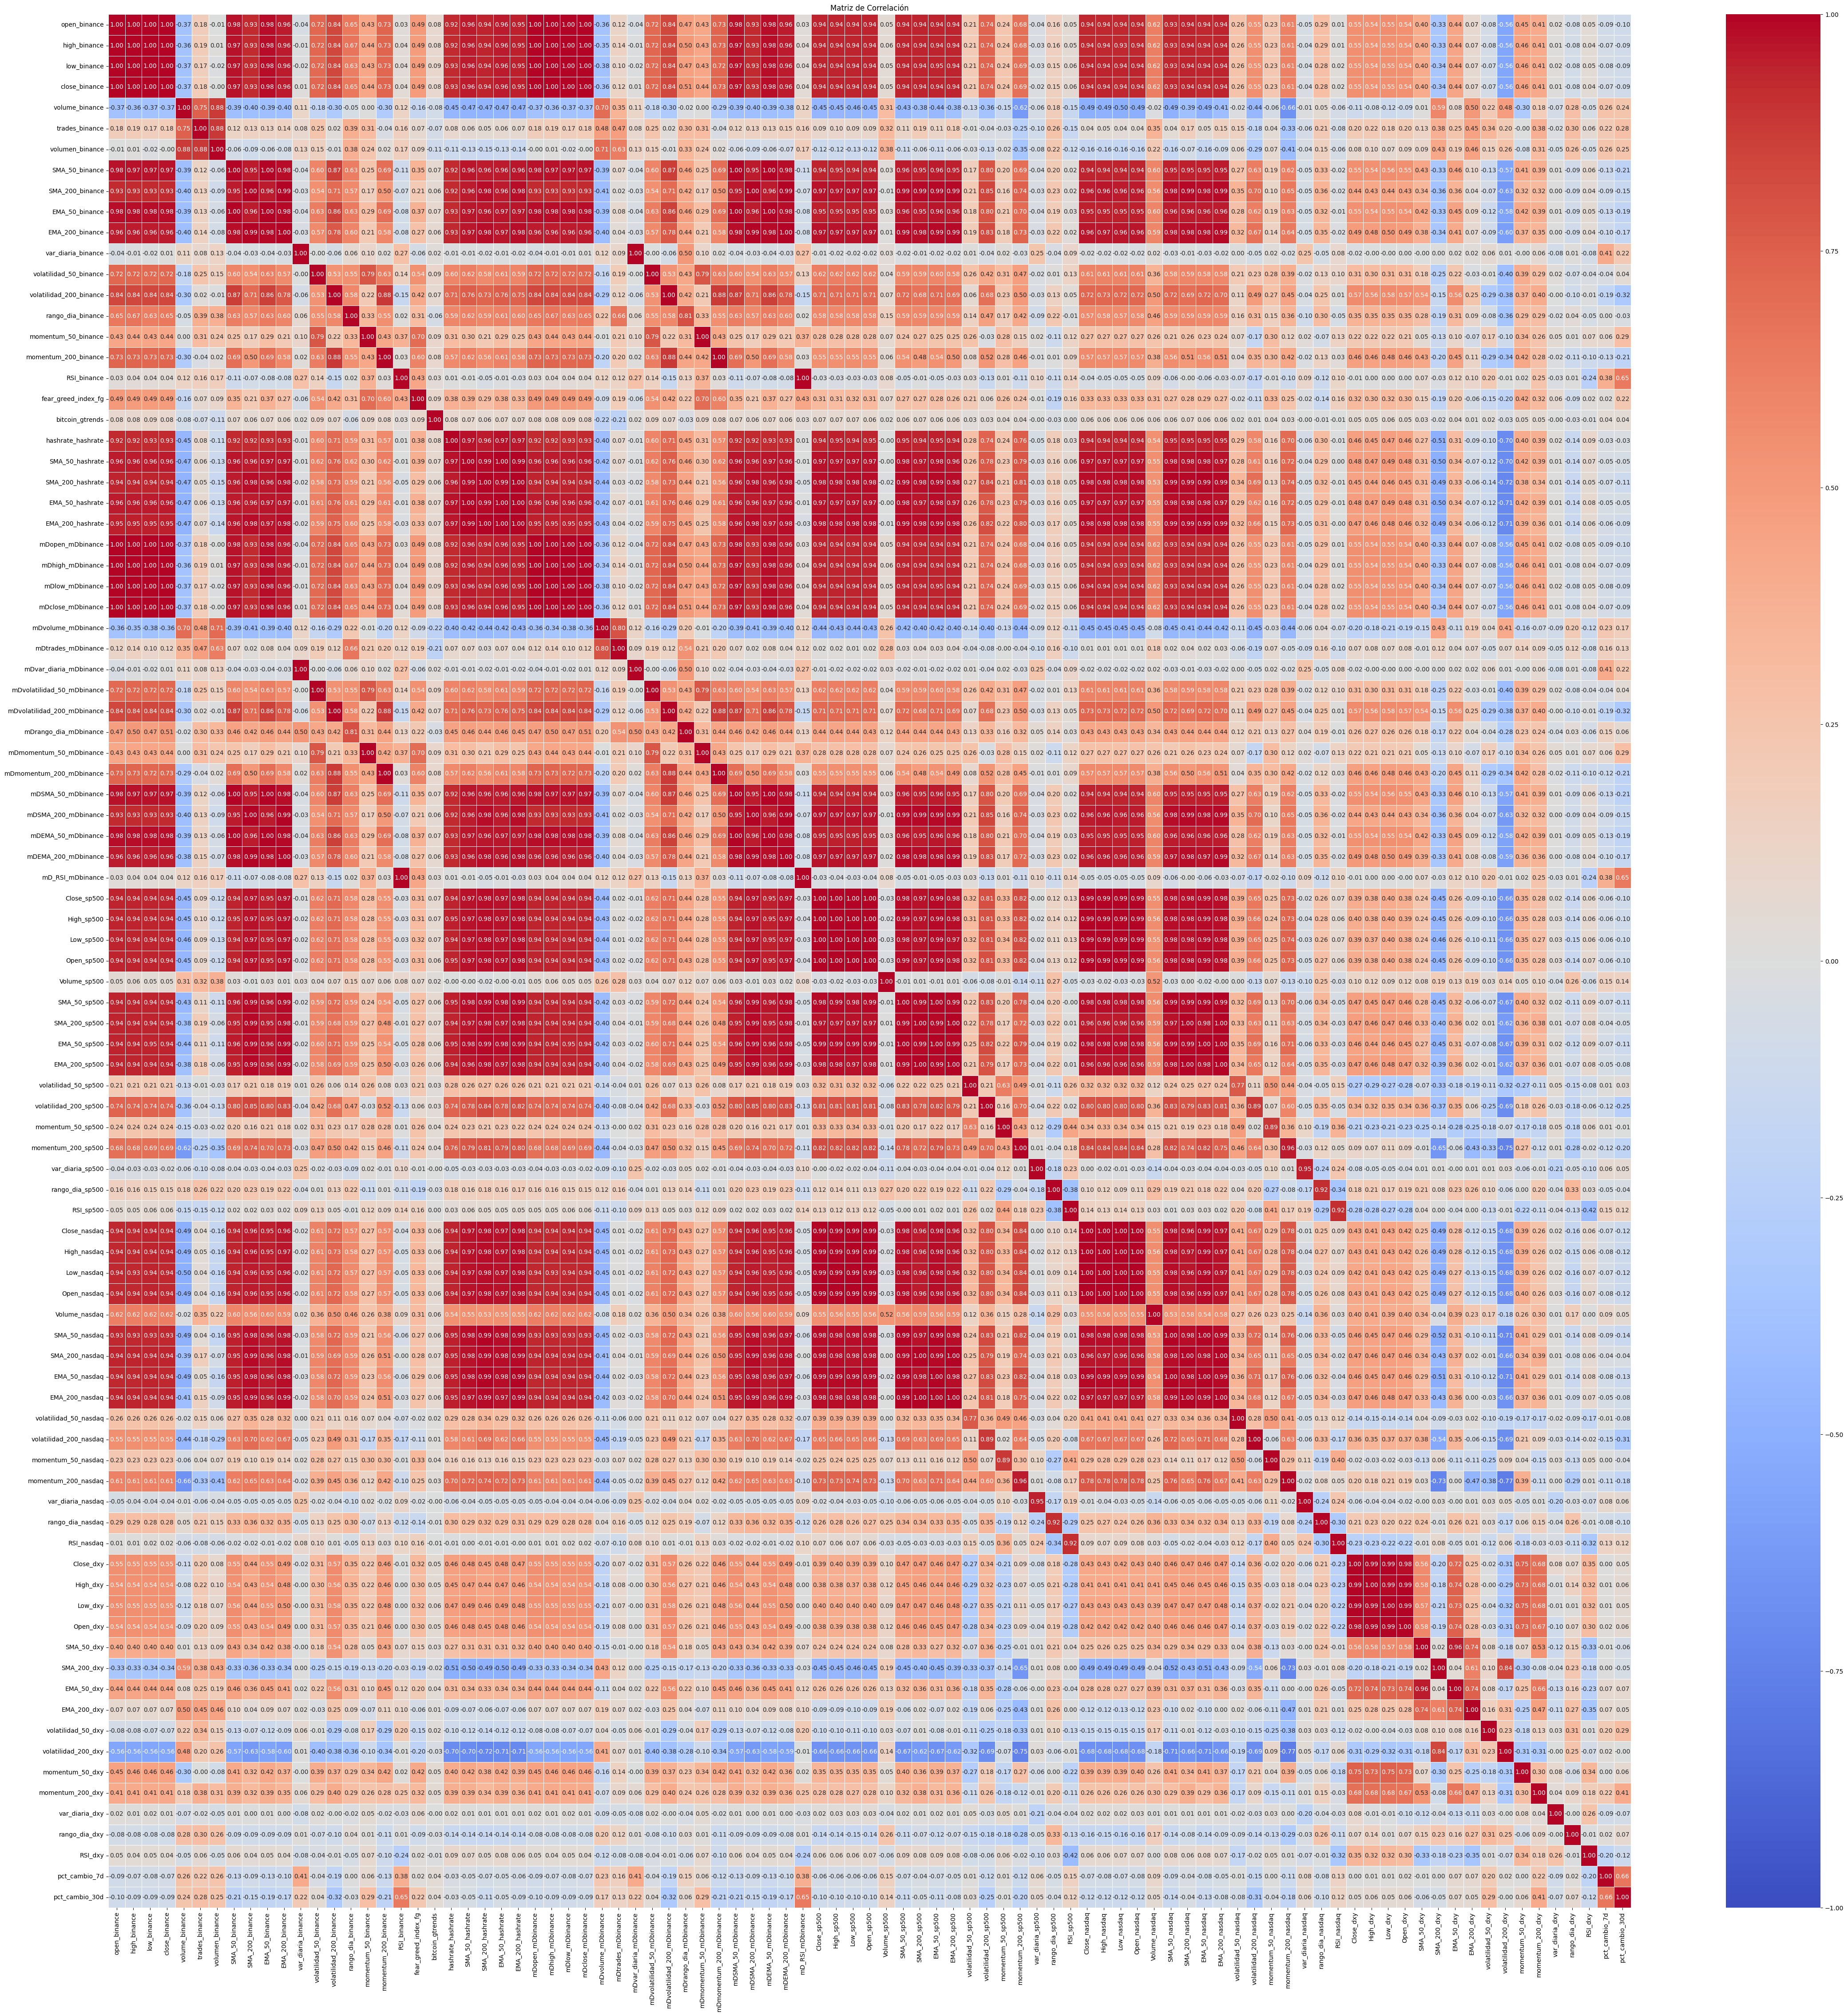

In [11]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Calcular la matriz de correlación
corr = df.corr()

# Ajustar tamaño del gráfico dinámicamente
fig_width = max(12, len(corr.columns) * 0.5)
fig_height = max(12, len(corr.columns) * 0.5)

# Graficar heatmap completo
plt.figure(figsize=(fig_width, fig_height))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f",
            linewidths=0.5, cbar=True, center=0, vmin=-1, vmax=1)

# Estética
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.title("Matriz de Correlación")

plt.tight_layout()
plt.show()



**Observación**: Al explorar el conjunto de datos, podemos detectar un alto grado de correlación entre muchas variables predictoras, especialmente dentro de grupos que representan fenómenos similares (por ejemplo, precios diarios o medias móviles). Por ello decidimos eliminar variables del conjunto de datos para evitar esta autocorrelación.